# Customer Residence Inference (CRI): walkthrough

**Question:** where do customers actually live and move *now*?

The address captured at account opening goes stale within a few years and is almost never updated. Branch-network planning, marketing and regional targets still relied on it. CRI infers location from **behavioural footprints**: branch visits, ATM withdrawals and card/POS spending.

*Synthetic data. In production, CRI ran on 1.54M customers at a Nigerian commercial bank.*

In [1]:
import warnings; warnings.filterwarnings("ignore")
import subprocess, sys, json, pandas as pd
from IPython.display import Image, display
subprocess.run([sys.executable, "data/generate_synthetic.py"], check=True, capture_output=True)
from src.cri import connect, run_models, relocation_summary, corridors, accuracy_vs_truth
con = connect()
con.execute("SELECT channel, SUM(n_events) AS events FROM events GROUP BY 1").df()

,channel,events
0,BRANCH,344369.0
1,ATM,1259406.0
2,POS,1723177.0


## 1. V1: one weighted model
`state score = 2 × branch visits + 1 × card/POS events`. Each customer is placed in their highest-scoring state, with a confidence tier based on the share and volume of evidence.

In [2]:
df = run_models(con)
v1 = relocation_summary(df, "v1_state", "v1_confidence")
print(f"relocated from account-opening state: {v1['relocated_share']:.1%}")
print("confidence mix:", v1["confidence_mix"])

relocated from account-opening state: 83.7%
confidence mix: {'HIGH': 0.9192, 'MEDIUM': 0.0611, 'LOW': 0.0197}


## 2. Why the final design separates branch and ATM
Branch visits and ATM withdrawals measure **different things**:
* **Branch = mobility.** People visit branches near work, on errands or on trips.
* **ATM = local convenience.** People withdraw cash near home.

Blending them mislabels commuters. The synthetic data can check this against a hidden true residence, which is never available in production. Take Ogun residents who work in Lagos:

,model,coverage,accuracy_all,accuracy_HIGH,share_HIGH,accuracy_ogun_residents
0,V1 weighted blend,0.998,0.985,0.997,0.919,0.838
1,Branch model,0.966,0.950,0.981,0.787,0.607
2,ATM model,0.995,0.995,1.000,0.898,0.990


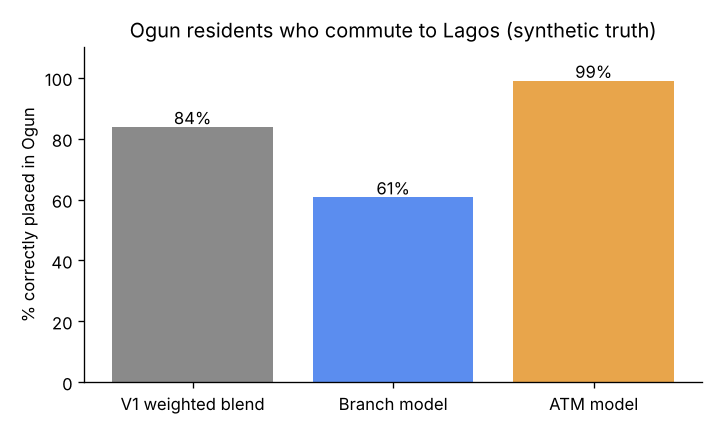

In [3]:
subprocess.run([sys.executable, "run_pipeline.py"], check=True, capture_output=True)
display(accuracy_vs_truth(con, df))
display(Image("reports/figures/commuter_test.png", width=520))

The ATM model places commuters at home. The branch model places them at work, which is also useful, but for a different question (*which branch should serve them?*). So the final design runs **two independent models with no blending**, each with its own state and confidence.

## 3. Where customers went

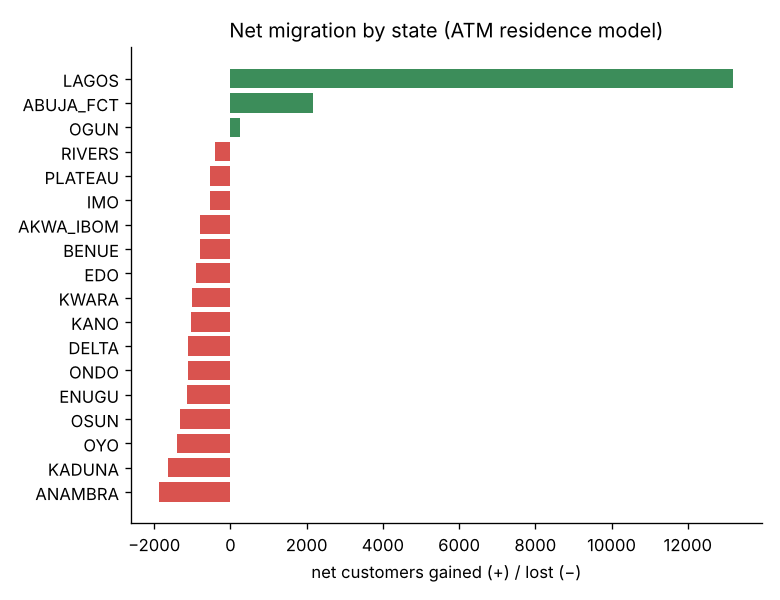

,open_state,inferred_state,customers
0,OYO,LAGOS,1466
1,RIVERS,LAGOS,1196
2,KANO,LAGOS,1104
3,ENUGU,LAGOS,1093
4,OGUN,LAGOS,1085
5,ANAMBRA,LAGOS,1076
6,ABUJA_FCT,LAGOS,977
7,KADUNA,LAGOS,973
8,DELTA,LAGOS,950
9,OSUN,LAGOS,796


In [4]:
display(Image("reports/figures/net_inflow_by_state.png", width=560))
display(corridors(con, "cri_atm", "atm_state"))

Every one of the top-10 corridors ends in **Lagos**, the same pattern found in the real data. Branch capacity, cash allocation and regional targets planned on account-opening addresses are pointing at the wrong map.